# Customer Churn Prediction: Which Customers Are Worth Saving?
Predict which customers will churn, compare 11 models, explain the drivers, and decide how many customers a retention campaign should contact.

Sections: clean → split → features tested → model comparison → test-set evaluation → calibration → drivers → customer value → campaign → sensitivity.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, roc_auc_score, average_precision_score, brier_score_loss,
                             log_loss, precision_score, recall_score, f1_score)
from scipy.stats import loguniform, randint, uniform
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv('telco_raw.csv'); df.shape

(7043, 21)

## 1. Clean
`TotalCharges` has 11 blanks, all tenure-0 customers who haven't been billed yet, so they are 0, not missing.

In [2]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['churn'] = (df['Churn'] == 'Yes').astype(int)
addons = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
for c in addons: df[c] = df[c].replace('No internet service', 'No')
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')
df['log_tenure'] = np.log1p(df['tenure'])
df['fiber_x_tenure'] = (df['InternetService'] == 'Fiber optic') * df['log_tenure']
print('churn rate:', round(df.churn.mean(), 3))

churn rate: 0.265


## 2. Split first, then everything else
Stratified 80/20 split **before** any tuning or feature testing. All model choices are made using 5-fold cross-validation on the training 80%. The test set is used for reporting only.

In [3]:
cat = ['gender','Partner','Dependents','PhoneService','MultipleLines','InternetService'] + addons + \
      ['Contract','PaperlessBilling','PaymentMethod']
train, test = train_test_split(df, test_size=0.2, stratify=df['churn'], random_state=SEED)
y_tr, y_te = train['churn'], test['churn']
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def make_pre(num):
    return ColumnTransformer([('num', StandardScaler(), num),
                              ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat)])
print(train.shape, test.shape)

(5634, 24) (1409, 24)


## 3. Features tested (logistic regression, 5-fold CV on training data only)
Judged on **log loss** (probability quality) because later steps multiply probabilities by dollars.

In [4]:
variants = {
  'Base: tenure, MonthlyCharges, SeniorCitizen':        ['tenure','MonthlyCharges','SeniorCitizen'],
  '+ TotalCharges':                                     ['tenure','MonthlyCharges','SeniorCitizen','TotalCharges'],
  'log(tenure) instead of tenure':                      ['log_tenure','MonthlyCharges','SeniorCitizen'],
  'log(tenure) + fiber x log(tenure)':                  ['log_tenure','MonthlyCharges','SeniorCitizen','fiber_x_tenure'],
  'log(tenure), MonthlyCharges dropped':                ['log_tenure','SeniorCitizen'],
}
rows = []
for name, num in variants.items():
    m = Pipeline([('pre', make_pre(num)), ('m', LogisticRegression(max_iter=3000))])
    ll = -cross_val_score(m, train[num+cat], y_tr, cv=cv, scoring='neg_log_loss')
    auc = cross_val_score(m, train[num+cat], y_tr, cv=cv, scoring='roc_auc')
    rows.append({'feature set': name, 'CV log loss': round(ll.mean(), 4), 'CV ROC-AUC': round(auc.mean(), 4)})
pd.DataFrame(rows)

,feature set,CV log loss,CV ROC-AUC
0,"Base: tenure, MonthlyCharges, SeniorCitizen",0.4176,0.8449
1,+ TotalCharges,0.4167,0.8460
2,log(tenure) instead of tenure,0.4100,0.8507
3,log(tenure) + fiber x log(tenure),0.4102,0.8507
4,"log(tenure), MonthlyCharges dropped",0.4100,0.8507


Why drop `MonthlyCharges`? It is almost entirely the price of the services a customer has. Regressing it on the service columns explains nearly all of it (below), so it duplicates them. Keeping it doesn't improve the model and it scrambles the coefficients. It is still used later for the dollar calculations.

In [5]:
svc = pd.get_dummies(train[['PhoneService','MultipleLines','InternetService'] + addons], drop_first=True)
print('R² of MonthlyCharges explained by services:', round(LinearRegression().fit(svc, train.MonthlyCharges).score(svc, train.MonthlyCharges), 4))
NUM = ['log_tenure','SeniorCitizen']
X_tr, X_te = train[NUM+cat], test[NUM+cat]

R² of MonthlyCharges explained by services: 0.9988


## 4. Model comparison: 11 models, selected on cross-validated log loss
Each model gets a randomised hyperparameter search (25 draws, 5-fold CV on training data), tuned and selected on **log loss**.

Why log loss and not accuracy or AIC?
- **Accuracy** only checks which side of 50% a prediction lands on, and is easy to inflate on imbalanced data: predicting "nobody churns" already scores 73.5%.
- **AIC** needs a likelihood and a parameter count. Logistic regression has both; random forests, boosting, SVMs, and k-NN don't, so AIC can't rank across these model families.
- **Cross-validated log loss** measures out-of-sample probability quality for any model. It is what AIC approximates, measured directly. It also matches what the campaign step needs: honest probabilities.

**Tie rule:** if a model's log loss is within noise of the best (paired fold-by-fold differences smaller than about two standard errors), the simplest tied model wins. Accuracy and ROC-AUC are reported alongside for comparison with other projects.

In [6]:
specs = {
  'Majority baseline':   (DummyClassifier(strategy='most_frequent'), {}),
  'Logistic regression': (LogisticRegression(solver='saga', max_iter=5000),
                          {'C': loguniform(1e-3, 1e2), 'l1_ratio': [0, 0.5, 1]}),
  'Decision tree':       (DecisionTreeClassifier(random_state=SEED),
                          {'max_depth': randint(2, 12), 'min_samples_leaf': randint(5, 200)}),
  'Random forest':       (RandomForestClassifier(random_state=SEED, n_jobs=1),
                          {'n_estimators': randint(200, 600), 'max_depth': [4, 6, 8, 10, None],
                           'min_samples_leaf': randint(1, 50), 'max_features': ['sqrt', 0.3, 0.5]}),
  'Extra trees':         (ExtraTreesClassifier(random_state=SEED, n_jobs=1),
                          {'n_estimators': randint(200, 600), 'max_depth': [4, 6, 8, 10, None],
                           'min_samples_leaf': randint(1, 50), 'max_features': ['sqrt', 0.3, 0.5]}),
  'Gradient boosting (sklearn)': (HistGradientBoostingClassifier(random_state=SEED),
                          {'learning_rate': loguniform(0.01, 0.3), 'max_depth': [2, 3, 4, 5, None],
                           'max_leaf_nodes': randint(4, 40), 'min_samples_leaf': randint(10, 200),
                           'l2_regularization': loguniform(1e-3, 10), 'max_iter': randint(50, 600)}),
  'XGBoost':             (XGBClassifier(random_state=SEED, n_jobs=1, eval_metric='logloss', verbosity=0),
                          {'n_estimators': randint(100, 600), 'learning_rate': loguniform(0.01, 0.3),
                           'max_depth': randint(2, 7), 'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.5, 0.5),
                           'min_child_weight': randint(1, 20), 'reg_lambda': loguniform(1e-2, 10)}),
  'LightGBM':            (LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1),
                          {'n_estimators': randint(100, 600), 'learning_rate': loguniform(0.01, 0.3),
                           'num_leaves': randint(4, 40), 'min_child_samples': randint(10, 200),
                           'subsample': uniform(0.6, 0.4), 'subsample_freq': [1], 'colsample_bytree': uniform(0.5, 0.5),
                           'reg_lambda': loguniform(1e-2, 10)}),
  'SVM (RBF kernel)':    (SVC(probability=True, random_state=SEED),
                          {'C': loguniform(1e-2, 1e2), 'gamma': loguniform(1e-3, 1)}),
  'k-nearest neighbours':(KNeighborsClassifier(),
                          {'n_neighbors': randint(5, 150), 'weights': ['uniform', 'distance']}),
  'Naive Bayes':         (GaussianNB(), {'var_smoothing': loguniform(1e-9, 1)}),
  'Neural network (MLP)':(MLPClassifier(max_iter=1000, early_stopping=True, random_state=SEED),
                          {'hidden_layer_sizes': [(16,), (32,), (64,), (32, 16)], 'alpha': loguniform(1e-5, 1),
                           'learning_rate_init': loguniform(1e-4, 1e-2)}),
}
scoring = {'accuracy': 'accuracy', 'log_loss': 'neg_log_loss', 'roc_auc': 'roc_auc'}
fitted, rows, folds = {}, [], {}
for name, (est, grid) in specs.items():
    pipe = Pipeline([('pre', make_pre(NUM)), ('m', est)])
    g = {f'm__{k}': v for k, v in grid.items()}
    s = RandomizedSearchCV(pipe, g, n_iter=25 if g else 1, cv=cv, scoring=scoring, refit='log_loss',
                           random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
    i = s.best_index_; r = s.cv_results_
    fitted[name] = s.best_estimator_
    folds[name] = np.array([-r[f'split{j}_test_log_loss'][i] for j in range(5)])
    rows.append({'model': name, 'CV log loss': -r['mean_test_log_loss'][i],
                 'CV ROC-AUC': r['mean_test_roc_auc'][i], 'CV accuracy': r['mean_test_accuracy'][i],
                 'best params': {k.replace('m__',''): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()}})
cmp = pd.DataFrame(rows).set_index('model').sort_values('CV log loss')
pd.set_option('display.max_colwidth', None)
cmp.round(4)

,CV log loss,CV ROC-AUC,CV accuracy,best params
model,,,,
Logistic regression,0.4097,0.8510,0.8088,"{'C': 0.1907, 'l1_ratio': 1}"
XGBoost,0.4103,0.8505,0.8067,"{'colsample_bytree': 0.5257, 'learning_rate': 0.0258, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 502, 'reg_lambda': 1.1018, 'subsample': 0.8124}"
LightGBM,0.4112,0.8502,0.8067,"{'colsample_bytree': 0.6504, 'learning_rate': 0.0263, 'min_child_samples': 90, 'n_estimators': 286, 'num_leaves': 5, 'reg_lambda': 0.3221, 'subsample': 0.6206, 'subsample_freq': 1}"
Gradient boosting (sklearn),0.4122,0.8492,0.8074,"{'l2_regularization': 5.2335, 'learning_rate': 0.1562, 'max_depth': 2, 'max_iter': 77, 'max_leaf_nodes': 23, 'min_samples_leaf': 39}"
Neural network (MLP),0.4139,0.8481,0.8058,"{'alpha': 0.0, 'hidden_layer_sizes': (16,), 'learning_rate_init': 0.0085}"
Random forest,0.4159,0.8479,0.8042,"{'max_depth': 8, 'max_features': 0.3, 'min_samples_leaf': 17, 'n_estimators': 249}"
Extra trees,0.4165,0.8465,0.8046,"{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 22, 'n_estimators': 508}"
SVM (RBF kernel),0.4170,0.8453,0.8021,"{'C': 2.6926, 'gamma': 0.0032}"
k-nearest neighbours,0.4352,0.8408,0.7977,"{'n_neighbors': 79, 'weights': 'uniform'}"


In [7]:
# Tie rule: paired fold differences vs the lowest-log-loss model
simplicity = {'Logistic regression': 1, 'Naive Bayes': 2, 'Decision tree': 3, 'k-nearest neighbours': 4,
              'SVM (RBF kernel)': 5, 'Neural network (MLP)': 6, 'Random forest': 7, 'Extra trees': 7,
              'Gradient boosting (sklearn)': 8, 'XGBoost': 8, 'LightGBM': 8, 'Majority baseline': 99}
lowest = cmp.index[0]; tie_rows = []
for m in cmp.index:
    d = folds[m] - folds[lowest]; se = d.std(ddof=1) / np.sqrt(len(d)) if m != lowest else 0
    tied = (m == lowest) or (d.mean() < 2 * se)
    tie_rows.append({'model': m, 'log loss gap vs lowest': round(d.mean(), 4), '2 × std. error': round(2 * se, 4),
                     'tied with lowest?': 'yes' if tied else 'no', 'simplicity rank': simplicity[m]})
ties = pd.DataFrame(tie_rows).set_index('model')
BEST = ties[ties['tied with lowest?'] == 'yes'].sort_values(['simplicity rank', 'log loss gap vs lowest']).index[0]
print('Lowest CV log loss:', lowest)
print('Tied with it:', list(ties[ties['tied with lowest?'] == 'yes'].index))
print('Selected (simplest tied model):', BEST)
ties

Lowest CV log loss: Logistic regression
Tied with it: ['Logistic regression', 'XGBoost', 'LightGBM']
Selected (simplest tied model): Logistic regression


,log loss gap vs lowest,2 × std. error,tied with lowest?,simplicity rank
model,,,,
Logistic regression,0.0000,0.0000,yes,1
XGBoost,0.0005,0.0031,yes,8
LightGBM,0.0015,0.0025,yes,8
Gradient boosting (sklearn),0.0025,0.0024,no,8
Neural network (MLP),0.0042,0.0024,no,6
Random forest,0.0061,0.0024,no,7
Extra trees,0.0067,0.0047,no,7
SVM (RBF kernel),0.0073,0.0027,no,5
k-nearest neighbours,0.0255,0.0184,no,4


## 5. Test-set results (all models, reported once)

In [8]:
probs = {n: m.predict_proba(X_te)[:, 1] for n, m in fitted.items()}
def top_decile_lift(y, p):
    k = int(len(p) * 0.1); return y.values[np.argsort(-p)[:k]].mean() / y.mean()
test_rows = []
for n, p in probs.items():
    pred = (p >= 0.5).astype(int)
    test_rows.append({'model': n, 'accuracy': accuracy_score(y_te, pred),
                      'precision': precision_score(y_te, pred, zero_division=0), 'recall': recall_score(y_te, pred),
                      'F1': f1_score(y_te, pred), 'ROC-AUC': roc_auc_score(y_te, p) if p.std() > 0 else 0.5,
                      'log loss': log_loss(y_te, np.clip(p, 1e-6, 1-1e-6)), 'Brier': brier_score_loss(y_te, p),
                      'top-10% lift': top_decile_lift(y_te, p)})
test_res = pd.DataFrame(test_rows).set_index('model').loc[cmp.index]
test_res.round(3)

,accuracy,precision,recall,F1,ROC-AUC,log loss,Brier,top-10% lift
model,,,,,,,,
Logistic regression,0.807,0.677,0.521,0.589,0.849,0.411,0.134,2.879
XGBoost,0.801,0.659,0.521,0.582,0.847,0.413,0.135,2.879
LightGBM,0.808,0.670,0.543,0.600,0.849,0.412,0.135,2.879
Gradient boosting (sklearn),0.804,0.666,0.527,0.588,0.848,0.413,0.135,2.852
Neural network (MLP),0.801,0.646,0.551,0.595,0.846,0.415,0.136,2.879
Random forest,0.800,0.665,0.495,0.567,0.845,0.416,0.136,2.852
Extra trees,0.795,0.647,0.500,0.564,0.844,0.417,0.136,2.826
SVM (RBF kernel),0.805,0.674,0.513,0.583,0.844,0.417,0.135,2.879
k-nearest neighbours,0.801,0.640,0.570,0.603,0.838,0.424,0.139,2.879


**Did the test set agree?** 2,000 bootstrap resamples of the test set: log loss and accuracy differences between the selected model and the other top models (negative log loss gap = selected model is better). This is a check, not a selection step.

In [9]:
rng = np.random.default_rng(SEED); yv = y_te.values; n = len(yv)
idx = [rng.integers(0, n, n) for _ in range(2000)]
ll = lambda y, p: log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1])
boot = []
for other in [m for m in cmp.index[:4] if m != BEST]:
    dl = [ll(yv[i], probs[BEST][i]) - ll(yv[i], probs[other][i]) for i in idx]
    da = [(((probs[BEST][i] >= .5) == yv[i]).mean() - ((probs[other][i] >= .5) == yv[i]).mean()) * 100 for i in idx]
    boot.append({'vs': other,
                 'log loss gap': round(np.mean(dl), 4), 'log loss 95% CI': f'[{np.percentile(dl,2.5):+.4f}, {np.percentile(dl,97.5):+.4f}]',
                 'accuracy gap (pts)': round(np.mean(da), 2), 'accuracy 95% CI': f'[{np.percentile(da,2.5):+.2f}, {np.percentile(da,97.5):+.2f}]'})
pd.DataFrame(boot).set_index('vs')

,log loss gap,log loss 95% CI,accuracy gap (pts),accuracy 95% CI
vs,,,,
XGBoost,-0.0018,"[-0.0055, +0.0018]",0.58,"[-0.14, +1.35]"
LightGBM,-0.0007,"[-0.0043, +0.0030]",-0.06,"[-0.78, +0.64]"
Gradient boosting (sklearn),-0.0016,"[-0.0057, +0.0024]",0.29,"[-0.50, +1.06]"


## 6. Calibration of the selected model
The campaign step multiplies probabilities by dollars, so they need to be honest: if the model says 40%, about 40% should churn. Selecting on log loss already favours well-calibrated models, but this checks it. Recalibration (Platt scaling) is used only if it improves **cross-validated training** log loss by more than 0.002. The test-set numbers are shown for reporting only.

CV log loss raw 0.4097 vs recalibrated 0.4098 -> use raw


Probabilities used for the campaign: raw


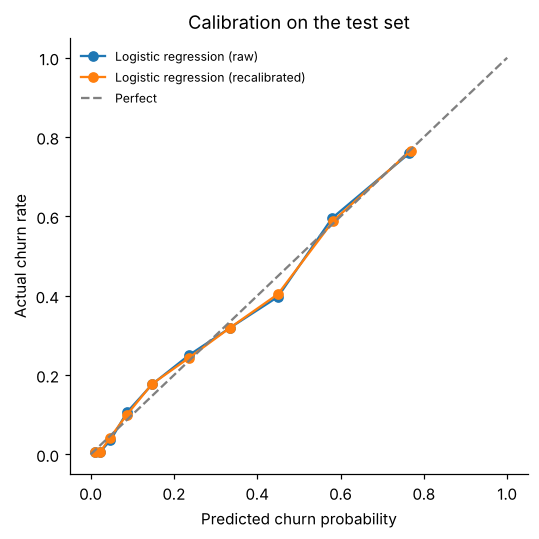

,log loss,Brier,accuracy
"Logistic regression (raw, test)",0.4111,0.1342,0.807
"Logistic regression (recalibrated, test)",0.4110,0.1342,0.807


In [10]:
# Decide on training data (CV), not the test set
cal = CalibratedClassifierCV(fitted[BEST], method='sigmoid', cv=5)
cv_raw = -cross_val_score(fitted[BEST], X_tr, y_tr, cv=cv, scoring='neg_log_loss').mean()
cv_cal = -cross_val_score(cal, X_tr, y_tr, cv=cv, scoring='neg_log_loss').mean()
USE_CAL = cv_raw - cv_cal > 0.002   # only if the gain is meaningful
print(f'CV log loss raw {cv_raw:.4f} vs recalibrated {cv_cal:.4f} -> use', 'recalibrated' if USE_CAL else 'raw')
cal.fit(X_tr, y_tr); p_cal = cal.predict_proba(X_te)[:, 1]
cal_tbl = pd.DataFrame({'log loss': [log_loss(y_te, probs[BEST]), log_loss(y_te, p_cal)],
                        'Brier': [brier_score_loss(y_te, probs[BEST]), brier_score_loss(y_te, p_cal)],
                        'accuracy': [accuracy_score(y_te, probs[BEST] >= .5), accuracy_score(y_te, p_cal >= .5)]},
                       index=[f'{BEST} (raw, test)', f'{BEST} (recalibrated, test)']).round(4)
P_MONEY = p_cal if USE_CAL else probs[BEST]
print('Probabilities used for the campaign:', 'recalibrated' if USE_CAL else 'raw')

fig, ax = plt.subplots(figsize=(5, 5))
for lab, p in [(f'{BEST} (raw)', probs[BEST]), (f'{BEST} (recalibrated)', p_cal)]:
    fp, mp = calibration_curve(y_te, p, n_bins=10, strategy='quantile'); ax.plot(mp, fp, marker='o', label=lab)
ax.plot([0, 1], [0, 1], '--', color='grey', label='Perfect')
ax.set_xlabel('Predicted churn probability'); ax.set_ylabel('Actual churn rate'); ax.legend(frameon=False, fontsize=8)
ax.set_title('Calibration on the test set'); plt.tight_layout(); plt.savefig('calibration.png', dpi=150); plt.show()
cal_tbl

## 7. What drives churn (tuned logistic regression)
The drivers come from logistic regression whichever model wins on accuracy, because its coefficients are directly readable. Odds ratio above 1 raises churn odds, below 1 lowers it. Numeric features are per one standard deviation.

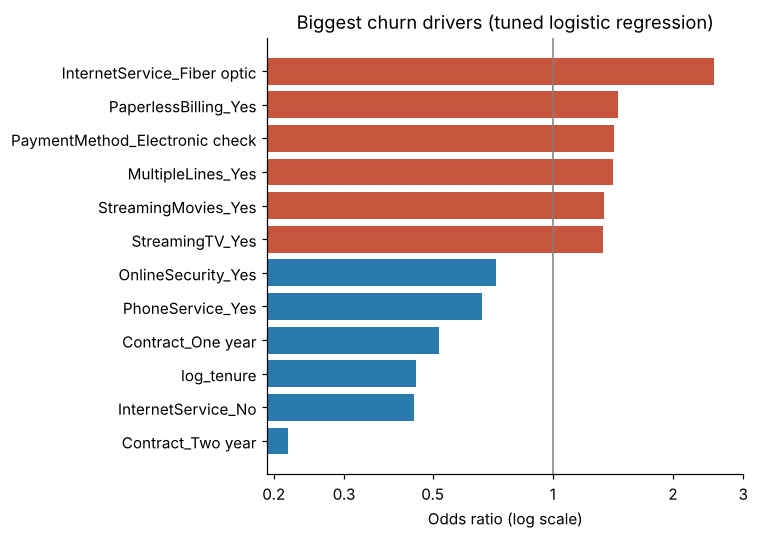

LR settings: {'C': np.float64(0.1907), 'l1_ratio': 1}
zeroed by regularisation: ['DeviceProtection_Yes', 'Partner_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check', 'gender_Male']


,odds_ratio
Contract_Two year,0.22
InternetService_No,0.45
log_tenure,0.45
Contract_One year,0.52
PhoneService_Yes,0.67
OnlineSecurity_Yes,0.72
TechSupport_Yes,0.77
Dependents_Yes,0.86
OnlineBackup_Yes,0.90
SeniorCitizen,1.07


In [11]:
lr = fitted['Logistic regression']
names = [n.split('__')[1] for n in lr.named_steps['pre'].get_feature_names_out()]
odds = pd.Series(np.exp(lr.named_steps['m'].coef_[0]), index=names).sort_values()
zeroed = sorted(odds[(odds - 1).abs() < 1e-6].index); odds = odds[(odds - 1).abs() >= 1e-6]
top = pd.concat([odds.head(6), odds.tail(6)]); top = top[~top.index.duplicated()]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=['#2a7ab0' if v < 1 else '#c8553d' for v in top.values])
ax.axvline(1, color='grey', lw=1); ax.set_xscale('log'); ax.set_xlabel('Odds ratio (log scale)')
ax.set_xticks([0.2, 0.3, 0.5, 1, 2, 3]); ax.set_xticklabels(['0.2', '0.3', '0.5', '1', '2', '3']); ax.minorticks_off()
ax.set_title('Biggest churn drivers (tuned logistic regression)'); plt.tight_layout()
plt.savefig('drivers.png', dpi=150); plt.show()
print('LR settings:', cmp.loc['Logistic regression', 'best params'])
print('zeroed by regularisation:', zeroed)
odds.round(2).to_frame('odds_ratio')

## 8. What is a saved customer worth?
Each row is a customer who either left last month or didn't, so each contract group's churn rate is treated as a **monthly** churn rate. A customer who leaves with monthly probability *h* stays about **1/h** more months on average, capped at 24.

**This is the project's biggest assumption.** It treats one month's churn as a steady rate, and it ignores that contract customers can't leave freely mid-term. Section 10 tests how much the answer depends on it. Computed on training data only.

In [12]:
def lifetime(cap):
    return (1 / train.groupby('Contract')['churn'].mean()).clip(upper=cap)
life = lifetime(24)
value_tbl = pd.concat([train.groupby('Contract')['churn'].mean().round(3).rename('monthly churn rate'),
                       life.round(1).rename('expected months remaining'),
                       train.groupby('Contract')['MonthlyCharges'].mean().round(2).rename('avg monthly bill')], axis=1)
value_tbl['value of a saved customer ($)'] = (value_tbl['expected months remaining'] * value_tbl['avg monthly bill']).round(0)
value_tbl

,monthly churn rate,expected months remaining,avg monthly bill,value of a saved customer ($)
Contract,,,,
Month-to-month,0.427,2.3,66.49,153.0
One year,0.111,9.0,65.50,590.0
Two year,0.029,24.0,60.87,1461.0


## 9. The campaign
For each customer: **expected value of calling = P(churn) × offer success rate × monthly bill × expected months remaining − offer cost.**

**Decision rule, fixed in advance: call everyone whose expected value is positive.** Nothing is tuned on the test set. Realised profit is then measured on the test set using who actually churned (only real churners can be saved).

For comparison, the same number of calls is made using churn probability alone.

Assumptions (placeholders): offer costs **$20** and saves **20%** of the churners it reaches.

In [13]:
SUCCESS, COST = 0.20, 20
te = test.copy(); te['p'] = P_MONEY
te['value_if_saved'] = te['MonthlyCharges'] * te['Contract'].map(life)
te['ev'] = te['p'] * SUCCESS * te['value_if_saved'] - COST

def realised(d, mask):
    s = d[mask]; return (s['churn'] * s['value_if_saved'] * SUCCESS).sum() - COST * len(s)

def compare(d, success=SUCCESS, cost=COST):
    ev = d['p'] * success * d['value_if_saved'] - cost
    k = int((ev > 0).sum())
    by_ev = ev > 0
    by_p = d['p'].rank(ascending=False, method='first') <= k
    f = lambda m: (d.loc[m, 'churn'] * d.loc[m, 'value_if_saved'] * success).sum() - cost * m.sum()
    return k, f(by_ev), f(by_p)

k, prof_ev, prof_p = compare(te)
rng = np.random.default_rng(SEED); bs = []
for _ in range(2000):
    b = te.iloc[rng.integers(0, len(te), len(te))].reset_index(drop=True)
    _, e, p = compare(b); bs.append((e, p, e - p))
bs = np.array(bs); ci = lambda j: np.percentile(bs[:, j], [2.5, 97.5]).round(0)
called = te[te.ev > 0]
camp = pd.DataFrame({'customers called': [k, k],
                     'actual churners reached': [int(called.churn.sum()), int(te[te['p'].rank(ascending=False, method='first') <= k].churn.sum())],
                     'profit ($)': [round(prof_ev), round(prof_p)],
                     'profit 95% CI ($)': [ci(0), ci(1)]},
                    index=['Rank by expected value (EV > 0 rule)', 'Rank by churn probability (same # calls)'])
print(f'Expected-value ranking minus probability ranking: ${prof_ev - prof_p:,.0f}, 95% CI {ci(2)}')
print('Test churners:', int(te.churn.sum()), 'of', len(te))
camp

Expected-value ranking minus probability ranking: $5,016, 95% CI [2359. 8084.]
Test churners: 374 of 1409


,customers called,actual churners reached,profit ($),profit 95% CI ($)
Rank by expected value (EV > 0 rule),447,201,5610,"[3005.0, 8834.0]"
Rank by churn probability (same # calls),447,260,593,"[-222.0, 1619.0]"


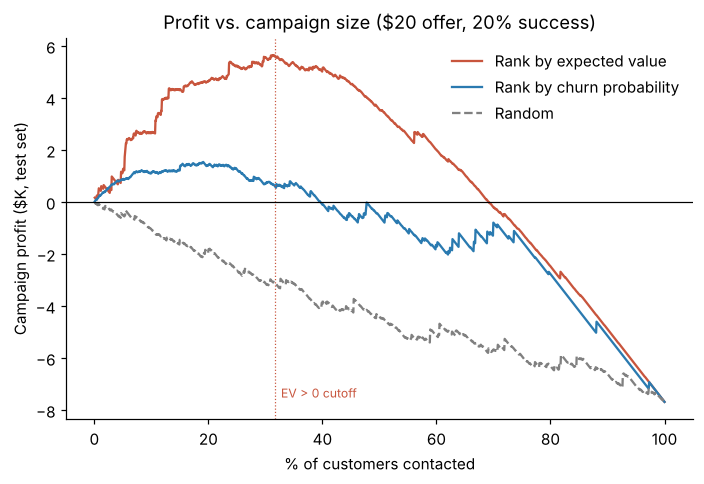

,called,churned,profit ($),share of called-list value
Contract,,,,
Month-to-month,260,169,1578,0.150
One year,103,25,2336,0.253
Two year,84,7,1695,0.597


In [14]:
s_ev = te.sort_values('ev', ascending=False); s_p = te.sort_values('p', ascending=False)
rand = te.sample(frac=1, random_state=SEED)
cum = lambda s: np.cumsum(s['churn'] * s['value_if_saved'] * SUCCESS - COST).values
x = np.arange(1, len(te) + 1) / len(te) * 100
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(x, cum(s_ev) / 1000, color='#c8553d', label='Rank by expected value')
ax.plot(x, cum(s_p) / 1000, color='#2a7ab0', label='Rank by churn probability')
ax.plot(x, cum(rand) / 1000, color='grey', ls='--', label='Random')
ax.axvline(k / len(te) * 100, color='#c8553d', lw=0.8, ls=':'); ax.text(k / len(te) * 100 + 1, ax.get_ylim()[0] * 0.9, 'EV > 0 cutoff', fontsize=8, color='#c8553d')
ax.axhline(0, color='black', lw=0.8); ax.set_xlabel('% of customers contacted'); ax.set_ylabel('Campaign profit ($K, test set)')
ax.set_title('Profit vs. campaign size ($20 offer, 20% success)'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('profit_curve.png', dpi=150); plt.show()

mix = called.groupby('Contract').agg(called=('churn', 'size'), churned=('churn', 'sum'))
mix['profit ($)'] = [round(realised(called, called.Contract == c)) for c in mix.index]
mix['share of called-list value'] = (called.groupby('Contract')['value_if_saved'].sum() / called['value_if_saved'].sum()).round(3)
mix

## 10. Sensitivity: how fragile is the answer?
**(a) The value assumption.** The 24-month cap mostly affects two-year customers, and their profit rests on very few churners. Re-run with a 12-month cap, and with two-year customers excluded entirely.

In [15]:
def lifetime_quarterly(cap):
    # If 'Churn' measures a quarter, not a month: convert to a monthly rate first
    q = train.groupby('Contract')['churn'].mean()
    return (1 / (1 - (1 - q) ** (1 / 3))).clip(upper=cap)

print('Lifetimes if churn is quarterly:', lifetime_quarterly(24).round(1).to_dict())
rows = []
for lab, life_fn, cap, excl in [('24-month cap (base case)', lifetime, 24, False), ('12-month cap', lifetime, 12, False),
                                ('Two-year customers excluded', lifetime, 24, True),
                                ('Churn measured over a quarter, not a month', lifetime_quarterly, 24, False)]:
    d = te.copy(); d['value_if_saved'] = d['MonthlyCharges'] * d['Contract'].map(life_fn(cap))
    if excl: d = d[d.Contract != 'Two year']
    kk, e, p = compare(d)
    rows.append({'scenario': lab, 'calls': kk, 'profit, rank by EV ($)': round(e), 'profit, rank by probability ($)': round(p),
                 'EV advantage ($)': round(e - p)})
pd.DataFrame(rows).set_index('scenario')

Lifetimes if churn is quarterly: {'Month-to-month': 5.9, 'One year': 24.0, 'Two year': 24.0}


,calls,"profit, rank by EV ($)","profit, rank by probability ($)",EV advantage ($)
scenario,,,,
24-month cap (base case),447,5610,593,5016
12-month cap,401,3923,878,3044
Two-year customers excluded,363,3914,1113,2801
"Churn measured over a quarter, not a month",749,26871,21503,5368


**(b) Offer cost and success rate**, using the EV > 0 rule and the base-case values.

In [16]:
grid = []
for cost in [10, 20, 50]:
    row = {'offer cost': f'${cost}'}
    for succ in [0.1, 0.2, 0.3]:
        kk, e, _ = compare(te, succ, cost); row[f'{int(succ*100)}% success'] = f'{kk} calls, ${e:,.0f}'
    grid.append(row)
pd.DataFrame(grid).set_index('offer cost')

,10% success,20% success,30% success
offer cost,,,
$10,"447 calls, $2,805","714 calls, $10,612","854 calls, $19,858"
$20,"89 calls, $312","447 calls, $5,610","619 calls, $13,302"
$50,"1 calls, $45","41 calls, $-747","142 calls, $1,170"


## Limitations
- **One snapshot.** No churn dates or usage history, so no time-based validation. Monthly churn rates come from a single month.
- **The lifetime formula is an assumption**, not something the data proves. It ignores contract terms and treats one month's churn as permanent. Section 10 shows the ranking advantage survives changing it, but the dollar totals move a lot.
- **The ranking comparison partly favours expected-value ranking by design**, because profit is scored with the same value formula used to rank. The comparison shows what happens *if* the values are right.
- **26.5% monthly churn is unusually high** for a real telco. Treat dollar values as a method demonstration.
- **Correlation, not causation.** Testing whether an offer works needs an A/B test.